In [14]:
import os
import pandas as pd

df_prices = pd.read_parquet("../data/raw/prices.parquet") # read prices saved by collect_data instead of calling the API again
df_news = pd.read_parquet("../data/processed/news_clean.parquet")

df_prices.head()

,symbol,timestamp,open,high,low,close,volume,trade_count,vwap
0,AAPL,2020-01-02 05:00:00+00:00,71.28,72.33,71.03,72.27,146217352.0,283489.0,71.84
1,AAPL,2020-01-03 05:00:00+00:00,71.50,72.33,71.35,71.57,154711256.0,280441.0,71.91
2,AAPL,2020-01-06 05:00:00+00:00,70.69,72.18,70.44,72.14,125599968.0,242868.0,71.66
3,AAPL,2020-01-07 05:00:00+00:00,72.15,72.40,71.58,71.80,118227136.0,227871.0,71.96
4,AAPL,2020-01-08 05:00:00+00:00,71.50,73.26,71.50,72.95,142736804.0,261773.0,72.50


In [13]:
df_news.head()

,ticker,created_at,headline,content,source,symbols,text_for_sentiment
0,AAPL,2026-10-15 18:33:56+00:00,Anthropic Needs Nearly $2.7B in Additional Mon...,"<figure class=""wp-block-image size-large""><img...",benzinga,"[AAPL, AMZN, BTCUSD, GOOG, META, MSFT, NVDA, Q...","<figure class=""wp-block-image size-large""><img..."
1,AAPL,2026-10-15 18:04:31+00:00,Michael Burry's 'Red October' Warning: Why QQQ...,<p>Falling bond yields are failing to revive t...,benzinga,"[AAPL, AMZN, DIA, GOOGL, META, MSFT, NVDA, QQQ...",<p>Falling bond yields are failing to revive t...
2,AAPL,2026-10-15 17:26:44+00:00,"Meta Announces Release Of Muse Spark Open, The...",,benzinga,"[AAPL, META, MSFT]","Meta Announces Release Of Muse Spark Open, The..."
3,AAPL,2026-10-15 17:04:44+00:00,'Apple and Meta team up to make Muse AI model ...,,benzinga,"[AAPL, META, MSFT]",'Apple and Meta team up to make Muse AI model ...
4,AAPL,2026-10-15 16:47:46+00:00,Apple Hits $5 Trillion Market Cap as Nvidia's ...,"<p><strong>Apple Inc.</strong> <a href=""https:...",benzinga,"[AAPL, CRWV, NVDA, ORCL, TSM]","<p><strong>Apple Inc.</strong> <a href=""https:..."


In [ ]:
import os
import pandas as pd


# Convert publication timestamps
if not df_news.empty:
    df_news["created_at"] = pd.to_datetime(
        df_news["created_at"], utc=True
    )

# Display dataset properties
print("Number of rows:", df_news.shape[0])
print("Number of columns:", df_news.shape[1])

print("\nColumn data types:")
print(df_news.dtypes)

print("\nMissing values:")
print(df_news.isnull().sum())

# Display article information
if not df_news.empty:
    display(df_news[[
        "headline",
        "content",
        "created_at",
        "symbols"
    ]].head())

    # Check how many articles contain full text
    has_content = (
        df_news["content"].fillna("").str.strip().ne("")
    )

    print("\nArticles with content:", has_content.sum())
    print("Articles without content:", (~has_content).sum())
    print(
        "Percentage with content:",
        round(has_content.mean() * 100, 2),
        "%"
    )

Number of rows: 27893
Number of columns: 7

Column data types:
ticker                                str
created_at            datetime64[us, UTC]
headline                              str
content                               str
source                                str
symbols                            object
text_for_sentiment                    str
dtype: object

Missing values:
ticker                0
created_at            0
headline              0
content               0
source                0
symbols               0
text_for_sentiment    0
dtype: int64


,headline,content,created_at,symbols
0,Anthropic Needs Nearly $2.7B in Additional Mon...,"<figure class=""wp-block-image size-large""><img...",2026-10-15 18:33:56+00:00,"[AAPL, AMZN, BTCUSD, GOOG, META, MSFT, NVDA, Q..."
1,Michael Burry's 'Red October' Warning: Why QQQ...,<p>Falling bond yields are failing to revive t...,2026-10-15 18:04:31+00:00,"[AAPL, AMZN, DIA, GOOGL, META, MSFT, NVDA, QQQ..."
2,"Meta Announces Release Of Muse Spark Open, The...",,2026-10-15 17:26:44+00:00,"[AAPL, META, MSFT]"
3,'Apple and Meta team up to make Muse AI model ...,,2026-10-15 17:04:44+00:00,"[AAPL, META, MSFT]"
4,Apple Hits $5 Trillion Market Cap as Nvidia's ...,"<p><strong>Apple Inc.</strong> <a href=""https:...",2026-10-15 16:47:46+00:00,"[AAPL, CRWV, NVDA, ORCL, TSM]"



Articles with content: 19826
Articles without content: 8067
Percentage with content: 71.08 %


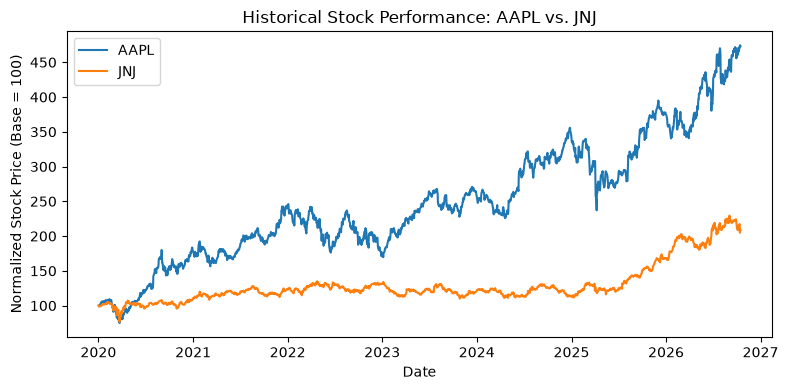

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

stocks = df_prices[df_prices["symbol"].isin(["AAPL", "JNJ"])].copy()
stocks = stocks.sort_values("timestamp")

close = stocks.pivot(index="timestamp", columns="symbol", values="close")
normalized = close / close.iloc[0] * 100

fig, ax = plt.subplots(figsize=(8, 4))

for symbol in ["AAPL", "JNJ"]:
    ax.plot(normalized.index, normalized[symbol], label=symbol)

ax.set_title("Historical Stock Performance: AAPL vs. JNJ")
ax.set_xlabel("Date")
ax.set_ylabel("Normalized Stock Price (Base = 100)")
ax.legend()

plt.tight_layout()
plt.show()

Number of columns: 9

Data types:
symbol                         str
timestamp      datetime64[us, UTC]
open                       float64
high                       float64
low                        float64
close                      float64
volume                     float64
trade_count                float64
vwap                       float64
dtype: object
AAPL number of observations: 1706
JNJ number of observations: 1706


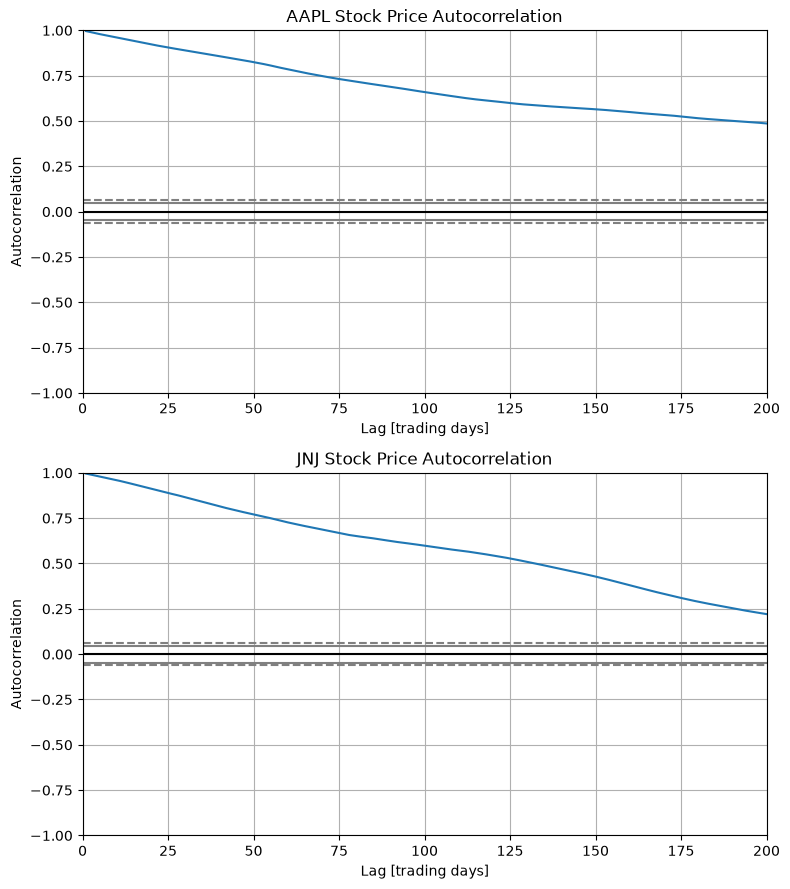

In [23]:
import os
import pandas as pd
import matplotlib.pyplot as plt


print("Number of columns:", df_prices.shape[1])
print("\nData types:")
print(df_prices.dtypes)


fig, axes = plt.subplots(2, 1, figsize=(8, 9), sharey=True)

for ax, symbol in zip(axes, ["AAPL", "JNJ"]):

    stock = df_prices[df_prices["symbol"] == symbol].copy()
    stock = stock.sort_values("timestamp")

    prices = stock["close"].dropna().reset_index(drop=True)
    print(f"{symbol} number of observations:", len(prices))

    pd.plotting.autocorrelation_plot(prices, ax=ax)

    ax.set_title(f"{symbol} Stock Price Autocorrelation")
    ax.set_xlabel("Lag [trading days]")
    ax.set_ylabel("Autocorrelation")

    # Explore the first 365 trading days
    ax.set_xlim(0, 200)
    ax.set_ylim(-1, 1)

plt.tight_layout()
plt.show()

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

negative 0.9405021071434021
positive 0.03458246961236
neutral 0.024915415793657303


,label,score
0,negative,0.940502
1,positive,0.034582
2,neutral,0.024915


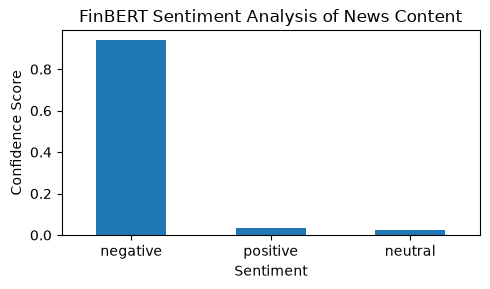

HEADLINE: Anthropic Needs Nearly $2.7B in Additional Monthly Revenue to Reach $100B Run Rate by Year-End
SOURCE: benzinga
PUBLISHED: 2026-10-15 18:33:56+00:00
SYMBOLS: ['AAPL' 'AMZN' 'BTCUSD' 'GOOG' 'META' 'MSFT' 'NVDA' 'QQQ' 'SPY' 'TSLA'
 'TSM' 'USO']

TEXT USED:
 PPI Spikes Please click here for an enlarged chart of Taiwan Semiconductor Mfg. Co. Ltd. (NYSE: TSM ) . Note the following: This article is about the big picture, not an individual stock.  The chart of TSM stock is being used to illustrate the point. TSM manufactures cutting edge AI chips for the likes of NVIDIA Corp (NVDA) and Advanced Micro Devices, Inc. (AMD). The chart shows TSM stock is falling after reporting record earnings. The chart shows TSM stock has fallen well below the low band of zone 1 (resistance). The chart shows TSM stock is well above the high band of zone 2 (support). RSI on the chart shows TSM is now oversold. The fact that TSM is falling after reporting record earnings is another data point showing tha

In [10]:
# Sentiment Analysis Experiment (News Content -> Structured Data)

import os
os.environ["USE_TF"] = "0"

import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from transformers import pipeline

sentiment = pipeline(
    "text-classification",
    model="ProsusAI/finbert",
    framework="pt",
    device="cpu"
)

# changed: use the article text (headline if no content) instead of "summary",
# and strip HTML tags so FinBERT reads plain text
summary = df_news.iloc[0]["text_for_sentiment"]
summary = BeautifulSoup(summary, "html.parser").get_text(" ", strip=True)

if isinstance(summary, str) and summary.strip():

    results = sentiment(
        summary,
        truncation=True,
        top_k=None
    )

    for result in results:
        print(result["label"], result["score"])

    df_sentiment = pd.DataFrame(results)

    display(df_sentiment)

    # Visualize sentiment scores
    df_sentiment.plot(
        x="label",
        y="score",
        kind="bar",
        legend=False,
        figsize=(5, 3)
    )

    plt.title("FinBERT Sentiment Analysis of News Content")
    plt.xlabel("Sentiment")
    plt.ylabel("Confidence Score")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

else:
    print("No article text available.")
article = df_news.iloc[0]
print("HEADLINE:", article["headline"])
print("SOURCE:", article["source"])
print("PUBLISHED:", article["created_at"])
print("SYMBOLS:", article["symbols"])

print("\nTEXT USED:\n", summary)

         negative     neutral    positive
count  300.000000  300.000000  300.000000
mean     0.280635    0.467372    0.251993
std      0.346474    0.366656    0.311615
min      0.007918    0.012080    0.007612
25%      0.022021    0.071338    0.029479
50%      0.084949    0.464073    0.088131
75%      0.499530    0.857061    0.404035
max      0.973995    0.952390    0.955564


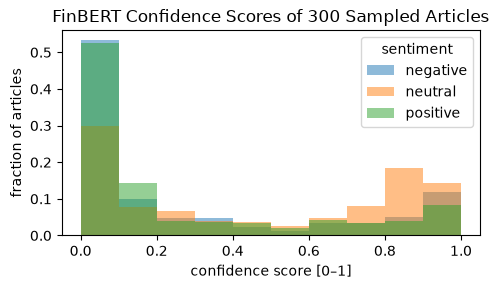

In [31]:
# Figure 4: FinBERT confidence scores across 300 sampled articles
# Uses the same FinBERT pipeline ("sentiment") and the same steps as Figure 1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup

sample = df_news.sample(n=300, random_state=0)

#  FinBERT convertion
texts = [
    BeautifulSoup(t, "html.parser").get_text(" ", strip=True)
    for t in sample["text_for_sentiment"]
]

results = sentiment(
    texts,
    truncation=True,
    top_k=None
)

correct_order = ["negative", "neutral", "positive"]
df_scores = pd.DataFrame(
    [{r["label"]: r["score"] for r in res} for res in results]
)[correct_order]

print(df_scores.describe())


plt.figure(figsize=(5, 3))

for c in correct_order:
    plt.hist(
        df_scores[c],
        alpha=0.5,
        label=c,
        range=(0, 1),
        bins=10,
        weights=np.ones(len(df_scores)) / len(df_scores)
    )

plt.legend(title="sentiment")
plt.ylabel("fraction of articles")
plt.xlabel("confidence score [0–1]")
plt.title("FinBERT Confidence Scores of 300 Sampled Articles")
plt.tight_layout()
plt.show()

In [32]:
print((df_scores > 0.9).mean().round(3))

negative    0.120
neutral     0.143
positive    0.083
dtype: float64
